<a href="https://colab.research.google.com/github/costpetrides/Numerical-Methods-GFD/blob/main/Lab_03_Finite_differences.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Πεπερασμένες διαφορές
________

- Πρώτη παράγωγος forward-difference:
$$
\begin{equation*}
\frac{\partial u_i}{\partial x} \simeq \frac{u_{i+1} - u_i}{h}
\end{equation*}
$$

- Πρώτη παράγωγος backward-difference:
$$
\begin{equation*}
\frac{\partial u_i}{\partial x} \simeq \frac{u_i - u_{i-1}}{h}
\end{equation*}
$$

- Πρώτη παράγωγος centered-difference:
$$
\begin{equation*}
\frac{\partial u_i}{\partial x} \simeq \frac{u_{i+1} - u_{i-1}}{2h}
\end{equation*}
$$

- Δεύτερη παράγωγος centered-difference:
$$
\begin{equation*}
\frac{\partial^2 u_i}{\partial x^2} \simeq \frac{u_{i-1} -2u_i + u_{i+1}}{h^2}
\end{equation*}
$$

### Επανάληψη στους πίνακες

### Επιλογή πολλαπλών στοιχείων (slicing) ενός πίνακα

In [1]:
import numpy as np

In [2]:
a = np.array([3, 5, 1, 0, 5, 7, 9])


|    Τιμές Πίνακα    |  3  |  5  |  1  |  0  |  5  |  7  |  9  |
| --------------------- | --- | --- | --- | --- | --- | --- | --- |
|                       |     |     |     |     |     |     |     |
| **Αρίθμηση**              | 0   | 1   | 2   | 3   | 4   | 5   | 6   |
| **Αρίθμηση από το τέλος** | -7  | -6  | -5  | -4  | -3  | -2  | -1  |


In [3]:
# πρώτο στοιχείο (με αρίθμηση 0) έως και το προτελευταίο

a[0:-1]


array([3, 5, 1, 0, 5, 7])

### Άσκηση

Εφαρμόστε τα κατάλληλα slices στον πίνακα `a` για τις περιπτώσεις που ακολουθούν:

In [4]:
a = np.array([1, 5, 9, 13, 17])

In [5]:
# δεύτερο έως και προτελευταίο στοιχείο
a[1:-1]

array([ 5,  9, 13])

In [6]:
# δεύτερο έως και τελευταίο στοιχείο
a[1:]

array([ 5,  9, 13, 17])

In [7]:
# τρίτο έως και τελευταίο στοιχείο
a[2:]

array([ 9, 13, 17])

### Δημιουργία μηδενικού πίνακα

    np.zeros((rows, cols))

> Προσοχή: τα `rows`, `cols` βρίσκονται μέσα σε ένα `tuple`


### Δημιουργία μηδενικού πίνακα με βάση έναν άλλον πίνακα
    np.zeros_like(a)

### Άσκηση

Δημιουργήστε έναν μηδενικό πίνακα με τρεις γραμμές και πέντε στήλες.

In [8]:
np.zeros((3, 5))

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]])

### Άσκηση

Δημιουργήστε έναν μηδενικό πίνακα με βάση τον πίνακα `a`:

In [9]:
a = np.array([
    [3, 5, 0],
    [1, 1, 2]
])


In [10]:
np.zeros_like(a)

array([[0, 0, 0],
       [0, 0, 0]])

### Δημιουργία κενού πίνακα

    np.full((rows, cols), np.nan)

> Προσοχή: τα `rows`, `cols` βρίσκονται μέσα σε ένα `tuple`


### Δημιουργία κενού πίνακα με βάση έναν άλλον πίνακα
    np.full(a.shape, np.nan)

### Άσκηση

Δημιουργήστε έναν κενό πίνακα με βάση τον πίνακα `a`:

In [11]:
a = np.array([
    [3, 5, 0],
    [1, 1, 2]
])


In [12]:
np.full(a.shape, np.nan)

array([[nan, nan, nan],
       [nan, nan, nan]])

### Πεπερασμένες διαφορές

### Backward-difference

In [13]:
a = np.array([1, 5, 7, 13, 18])


Για λόγους απλότητας, ας θεωρήσουμε αρχικά ότι το χωρικό βήμα $h$ είναι ίσο με τη μονάδα ($h = 1$).

Θέλουμε να δημιουργήσουμε έναν νέο πίνακα, όπου κάθε στοιχείο του είναι ίσο
με το αντίστοιχο στοιχείο του $a$ μείον το προηγούμενο στοιχείο του $a$.

$b_i = a_i - a_{i-1}$

Προσοχή: το $b_i$ μπορεί να υπολογιστεί μόνο από το δεύτερο έως και το τελευταίο στοιχείο.


Για να έχουν οι πίνακες `a` και `b` το ίδιο πλήθος στοιχείων, πρέπει αρχικά να δημιουργηθεί ένας κενός πίνακας `b` με το ίδιο μέγεθος με τον `a`.

In [14]:
b = np.full(a.shape, np.nan)
print(b)

[nan nan nan nan nan]


Διατρέχουμε τον πίνακα $a$ και κάθε φορά αφαιρούμε από το $a_i$ το προηγούμενο του.

In [15]:
b[1:] = a[1:] - a[0:-1]
print(b)

[nan  4.  2.  6.  5.]


Το παραπάνω θα μπορούσε να υπολογιστεί κάνοντας χρήση ενός for loop:

In [16]:
b = np.full(a.shape, np.nan)
for i in range(1, len(a)):
    b[i] = a[i] - a[i-1]
print(b)

[nan  4.  2.  6.  5.]


Ωστόσο, η χρήση ενός for loop σε έναν NumPy Array συνεπάγεται αρκετά μεγαλύτερο υπολογιστικό κόστος.

Αυτό είναι εμφανές στο παρακάτω, πιο απαιτητικό, παράδειγμα.

In [17]:
a = np.arange(0, 10**7, 1)
b = np.full(a.shape, np.nan)
b[1:] = a[1:] - a[0:-1]

In [18]:
a = np.arange(0, 10**7, 1)
b = np.full(a.shape, np.nan)
for i in range(1, len(a)):
    b[i] = a[i] - a[i-1]

Τι θα συμβεί εάν βάλουμε `10**8`;

In [19]:
# a = np.arange(0, 10**8, 1)
# b = np.full(a.shape, np.nan)
# for i in range(1, len(a)):
#     b[i] = a[i] - a[i-1]

# Με 10**8 στοιχεία, οι δύο πίνακες απαιτούν περίπου 1.6 GB μνήμης.
# Η εκτέλεση του βρόχου γίνεται επίσης σημαντικά πιο αργή.

### Άσκηση

Υπολογίστε τις πεπερασμένες διαφορές για τις παρακάτω περιπτώσεις.

> Μην ξεχνάτε τη δημιουργία του κενού πίνακα.

#### Forward-difference

Υπολογίστε τον παρακάτω πίνακα:

$e_i = d_{i+1} - d_i$

In [20]:
d = np.array([1, 5, 7, 13, 18])

In [37]:
e = np.full(d.shape, np.nan)
e[:-1] = d[1:] - d[:-1]
print(e)

[ 4.  2.  6.  5. nan]


#### Centered-difference

Υπολογίστε τον παρακάτω πίνακα:

$g_i = (f_{i+1} - f_{i-1})/2$

In [22]:
f = np.array([1, 5, 7, 13, 18])

In [23]:
g = np.full(f.shape, np.nan)
g[1:-1] = (f[2:] - f[:-2]) / 2
g

array([nan, 3. , 4. , 5.5, nan])

### Πεπερασμένες διαφορές - Εφαρμογή στις παραγώγους

$-3 \leq x \leq 3, \quad h = 0.01 \quad$

$u(x) = x^2$

$u'(x) = 2x$

$u''(x) = 2$

In [24]:
h = 0.01
x = np.arange(-3, 3 + h, h)
u = x**2

In [34]:
# πρώτη παράγωγος (αναλυτική λύση)
analytical_1st_der = 2 * x

In [35]:
# δεύτερη παράγωγος (αναλυτική λύση)
# τιμή ίση με 2 για όλα τα σημεία x
analytical_2nd_der = np.repeat(2, repeats=len(x))

- Πρώτη παράγωγος forward-difference:

$$
\begin{equation*}
\frac{\partial u_i}{\partial x} \simeq \frac{u_{i+1} - u_i}{h}
\end{equation*}
$$


In [42]:
forward_1st_der = np.full(u.shape, np.nan)

forward_1st_der[0:-1] = (u[1:] - u[0:-1]) / h

### Άσκηση

Υπολογίστε τις παραγώγους με πεπερασμένες διαφορές στις περιπτώσεις που ακολουθούν:

- Πρώτη παράγωγος backward-difference:
$$
\begin{equation*}
\frac{\partial u_i}{\partial x} \simeq \frac{u_i - u_{i-1}}{h}
\end{equation*}
$$


In [28]:
backward_1st_der = np.full(u.shape, np.nan)
backward_1st_der[1:] = (u[1:] - u[:-1]) / h

- Πρώτη παράγωγος centered-difference:
$$
\begin{equation*}
\frac{\partial u_i}{\partial x} \simeq \frac{u_{i+1} - u_{i-1}}{2h}
\end{equation*}
$$


> Προσοχή: ο παρονομαστής θέλει παρένθεση

In [29]:
centered_1st_der = np.full(u.shape, np.nan)
centered_1st_der[1:-1] = (u[2:] - u[:-2]) / (2*h)

- Δεύτερη παράγωγος centered-difference:
$$
\begin{equation*}
\frac{\partial^2 u_i}{\partial x^2} \simeq \frac{u_{i-1} -2u_i + u_{i+1}}{h^2}
\end{equation*}
$$


In [45]:
centered_2nd_der = np.full(u.shape, np.nan)
centered_2nd_der[1:-1] = (u[:-2] - 2*u[1:-1] + u[2:]) / h**2

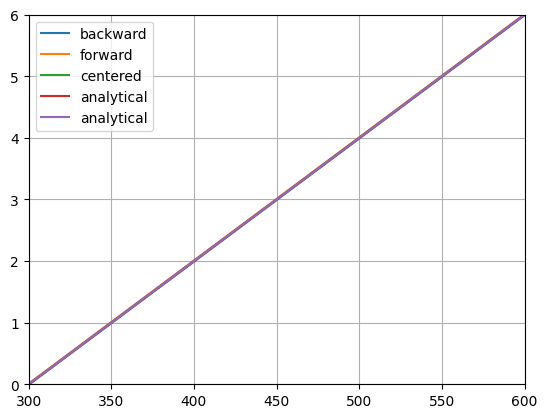

In [52]:
import matplotlib.pyplot as plt

plt.plot(backward_1st_der, label="backward")
plt.plot(forward_1st_der, label="forward")
plt.plot(centered_1st_der, label="centered")
plt.plot(analytical_1st_der, label="analytical")
plt.grid()
plt.xlim(300,600)
plt.ylim(0,6)
plt.plot(analytical_1st_der, label="analytical")
plt.legend()
plt.show()

### Υπολογισμός της ακρίβειας των αριθμητικών σχημάτων

Mean absolute error (MAE):

$$
\begin{equation*}
MAE = \frac{\sum_{i=1}^n |y_{analytical} - y_{numerical}|}{n}
\end{equation*}
$$

### Άσκηση

Έχουμε ορίσει μια καινούργια συνάρτηση η οποία θα υπολογίζει το σφάλμα MAE.

Εφαρμόστε τη συνάρτηση για να βρείτε την ακρίβεια των πεπερασμένων
διαφορών για την περίπτωση της 1ης παραγώγου του $x^2$.

In [31]:
def compute_mae(y_analytical, y_numerical):
    mae = np.nanmean(np.abs(y_analytical - y_numerical))
    return mae

In [38]:
# εφαρμόστε τρεις φορές τη συνάρτηση compute_mae για τις περιπτώσεις της πρώτης παραγώγου (backward, forward, centered)
mae_backward = compute_mae(analytical_1st_der, backward_1st_der)
mae_forward = compute_mae(analytical_1st_der, forward_1st_der)
mae_centered = compute_mae(analytical_1st_der, centered_1st_der)

print(f"Backward MAE: {mae_backward:.3e}")
print(f"Forward MAE:  {mae_forward:.3e}")
print(f"Centered MAE: {mae_centered:.3e}")

Backward MAE: 1.000e-02
Forward MAE:  1.000e-02
Centered MAE: 6.381e-14


In [33]:
mae_second = compute_mae(analytical_2nd_der, centered_2nd_der)
print(f"Second derivative MAE: {mae_second:.6e}")

Second derivative MAE: 2.927304e-12
